# BrainGuard: brain-tumour MRI classifier validated on unseen patients (walkthrough)

I built a classifier that identifies the tumour type (glioma, meningioma, pituitary) from one contrast-enhanced T1 MRI slice. Validated on 233 patients with patient-grouped cross-validation, the final ResNet50 model reaches **90.1% balanced accuracy** (macro AUC 0.983) on patients it never saw. It was selected from six architectures compared on identical folds, then tested for robustness and explained with SHAP and Grad-CAM scored against radiologists' tumour outlines.

This notebook walks through how it was built, and why patient-level validation was essential: the popular Kaggle benchmark leaks scans and patients between its splits.

It reads the reports and **per-image predictions** saved in the repository and recomputes the key numbers. It needs no images and no GPU. To regenerate everything from the raw data, use `notebooks/run_on_colab.ipynb`.

| Part | Question |
|---|---|
| 1 | What is wrong with the popular Kaggle benchmark? (data validation: duplicates, shared patients, shortcuts) |
| 1b | Kaggle data: cleaning and validation checks, computed live |
| 2a | figshare data: validation and exploratory analysis |
| 2b | Preprocessing, feature engineering and patient-grouped splitting |
| 2 | How accurate is the final model on patients it has never seen? |
| 3 | How much does leakage inflate accuracy, measured directly? |
| 4 | Does transfer learning or class weighting help? Which architecture is best? |
| 5 | Is the model robust to image-quality changes? |
| 6 | Do the explanations (SHAP, Grad-CAM) point at the tumour? |
| 7 | Hypothesis tests and conclusions |

In [1]:
import json, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix

ROOT = Path("..") if (Path("..") / "reports").exists() else Path("BrainGuard-MRI-Tumor-Detection")
if not (ROOT / "reports").exists():          # opened on its own (e.g. in Colab): fetch the repository
    subprocess.run(["git", "clone", "-q", "https://github.com/Muneera-DSA/BrainGuard-MRI-Tumor-Detection.git"], check=True)
REP, FIG, PRED = ROOT / "reports", ROOT / "reports" / "figures", ROOT / "results" / "predictions"
DATA = ROOT / "results" / "data"
import sys; sys.path.insert(0, str(ROOT / "src"))
CLASSES = ["glioma", "meningioma", "pituitary"]
res = json.loads((REP / "results.json").read_text())
def predicted(df, classes=CLASSES):
    return np.array(classes)[df[[f"p_{c}" for c in classes]].to_numpy().argmax(axis=1)]
print("prediction files:", sorted(p.name for p in PRED.glob("*.csv")))

prediction files: ['cnn_patient.csv', 'convnext_tiny_patient.csv', 'densenet121_patient.csv', 'effnet_image.csv', 'effnet_patient.csv', 'effnet_patient_cw.csv', 'kaggle_effnet.csv', 'mobilenetv3_patient.csv', 'resnet50_final.csv', 'resnet50_patient.csv', 'robustness_effnet_patient.csv', 'robustness_resnet50_final.csv']


## Part 1: the Kaggle benchmark is contaminated

Testing images with an identical file in Training:           103 (7.9%)
Testing images with a near-copy in Training (pixel r >= 0.95):  710 (54.2%)


,min_correlation,test_images_with_a_copy_in_train,test_images_with_a_copy_in_train_share,groups_with_conflicting_labels
0,0.900,1046,0.798,15
1,0.950,710,0.542,1
2,0.980,504,0.384,0
3,0.995,477,0.364,0


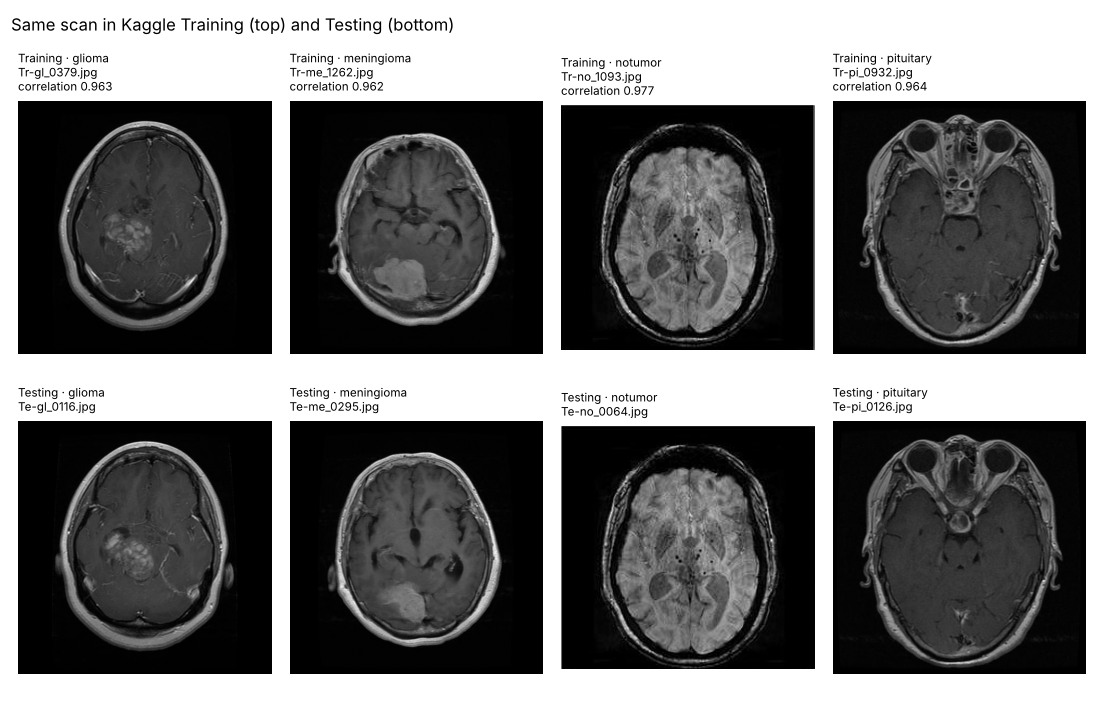

In [2]:
audit = json.loads((REP / "kaggle_audit.json").read_text())
ex, near = audit["exact"], audit["near"]
print(f"Testing images with an identical file in Training:          {ex['test_images_with_a_copy_in_train']:4d} ({ex['test_images_with_a_copy_in_train_share']:.1%})")
print(f"Testing images with a near-copy in Training (pixel r >= 0.95): {near['test_images_with_a_copy_in_train']:4d} ({near['test_images_with_a_copy_in_train_share']:.1%})")
display(pd.DataFrame(audit["threshold_sensitivity"])[["min_correlation", "test_images_with_a_copy_in_train", "test_images_with_a_copy_in_train_share", "groups_with_conflicting_labels"]].round(3))
display(Image(filename=str(FIG / "kaggle_duplicates.png")))

Duplicates are detected by perceptual hash and then confirmed by pixel correlation. Below r = 0.95, matched pairs start to carry different labels, which shows they are different brains. That is why 0.95 is the threshold.

Kaggle tumour images matched back to their figshare originals: 1,744 (34.7%)
Patients in Kaggle Testing: 120, of whom also in Kaggle Training: 114
Matched Testing images that come from a Training patient: 171 of 178 (96%)

Model given ONLY file properties (size, colour mode, file size; no pixels):
  tumour vs no tumour: AUC 0.984, accuracy 94.0%
  one rule, 'not 512x512 -> no tumour': accuracy 90.5%


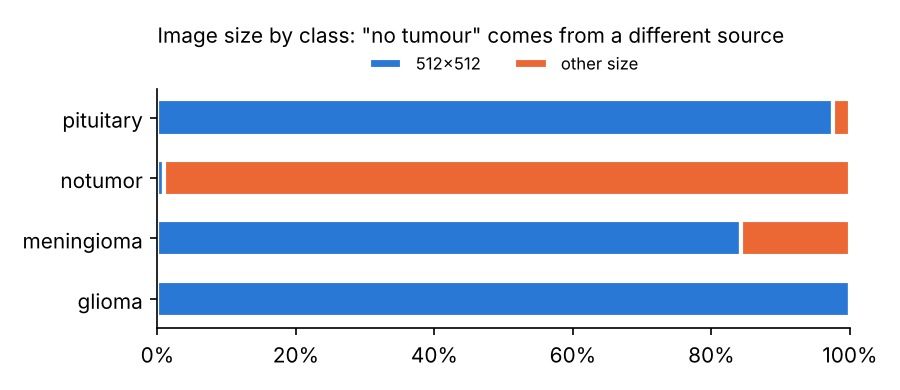

In [3]:
cw = json.loads((REP / "kaggle_crosswalk.json").read_text())
print(f"Kaggle tumour images matched back to their figshare originals: {cw['matched_to_figshare']:,} ({cw['matched_share_of_tumour_images']:.1%})")
print(f"Patients in Kaggle Testing: {cw['patients_in_kaggle_test']}, of whom also in Kaggle Training: {cw['patients_in_both']}")
print(f"Matched Testing images that come from a Training patient: {cw['test_images_from_training_patients']} of {cw['matched_test_images']} "
      f"({cw['test_images_from_training_patients_share']:.0%})")
sc = json.loads((REP / "kaggle_shortcut.json").read_text())
print(f"\nModel given ONLY file properties (size, colour mode, file size; no pixels):")
print(f"  tumour vs no tumour: AUC {sc['binary']['auc']['auc']:.3f}, accuracy {sc['binary']['accuracy']:.1%}")
print(f"  one rule, 'not 512x512 -> no tumour': accuracy {sc['rule_not_512_means_no_tumour']['accuracy']:.1%}")
display(Image(filename=str(FIG / "kaggle_size_by_class.png")))

**Conclusion of Part 1:** high accuracy on this benchmark is not evidence of tumour recognition. Half of its Testing images are near-copies of Training images, its Testing patients are Training patients, and the "no tumour" class can be recognised from file size alone.

The model in Part 2 is therefore built on the figshare dataset, which has patient IDs, one source and radiologist tumour outlines. It predicts **tumour type** only.

## Part 1b: Kaggle data, cleaning and validation checks (computed live)

`results/data/kaggle_index.csv.gz` holds one row per Kaggle image: its size, colour mode, file size, duplicate group (from the hash-and-correlation audit), and the figshare patient it was matched to. The checks below are recomputed from that table.

In [4]:
k = pd.read_csv(DATA / "kaggle_index.csv.gz", dtype={"pid": str})
print(f"{len(k):,} images")
display(pd.crosstab(k.label, k.split, margins=True).rename_axis(None, axis=1))
print("Image size by class (a model can learn the class from the size alone):")
display(pd.crosstab(k.label, k.size_group.where(k.size_group.isin(["512x512"]), "other sizes"), normalize="index").round(3))
print("Colour mode by class:")
display(pd.crosstab(k.label, k["mode"]))

7,023 images


,test,train,All
label,,,
glioma,300,1321,1621
meningioma,306,1339,1645
notumor,405,1595,2000
pituitary,300,1457,1757
All,1311,5712,7023


Image size by class (a model can learn the class from the size alone):


size_group,512x512,other sizes
label,,
glioma,1.000,0.000
meningioma,0.843,0.157
notumor,0.010,0.990
pituitary,0.976,0.024


Colour mode by class:


mode,L,P,RGB,RGBA
label,,,,
glioma,1426,0,195,0
meningioma,708,0,937,0
notumor,29,1,1967,3
pituitary,930,0,827,0


In [5]:
exact = k.groupby("exact_group").filter(lambda g: len(g) > 1)
near = k.groupby("dup_group").filter(lambda g: len(g) > 1)
span = near.groupby("dup_group").split.nunique()
conflict = near.groupby("dup_group").label.nunique()
print(f"byte-identical files in groups of 2+: {len(exact):,} images in {exact.exact_group.nunique():,} groups")
print(f"near-duplicates (pixel r >= 0.95) in groups of 2+: {len(near):,} images in {near.dup_group.nunique():,} groups")
print(f"  groups spanning Training AND Testing: {(span > 1).sum():,}")
print(f"  groups whose copies carry DIFFERENT labels: {(conflict > 1).sum()}")
test = k[k.split == "test"]
train_groups = set(k.loc[k.split == "train", "dup_group"])
print(f"Testing images with a near-copy in Training: {test.dup_group.isin(train_groups).mean():.1%}")
m = k[k.pid.notna()]
tr_p, te_p = set(m.loc[m.split == "train", "pid"]), set(m.loc[m.split == "test", "pid"])
print(f"figshare patients behind Kaggle Testing images: {len(te_p)}, also behind Training images: {len(te_p & tr_p)}")

byte-identical files in groups of 2+: 491 images in 194 groups
near-duplicates (pixel r >= 0.95) in groups of 2+: 3,226 images in 808 groups
  groups spanning Training AND Testing: 502
  groups whose copies carry DIFFERENT labels: 1
Testing images with a near-copy in Training: 54.2%
figshare patients behind Kaggle Testing images: 120, also behind Training images: 114


These are the validation findings behind Part 1, reproduced from the index. A valid test set needs none of them: no copies across splits, no shared patients, and no class that can be read from the file size.

## Part 2a: figshare data, validation and exploratory analysis

The model is built on the figshare dataset of Cheng et al. (CC BY 4.0): contrast-enhanced T1 slices, each with a radiologist's tumour outline and a patient ID. `results/data/figshare_metadata.csv` has one row per slice.

In [6]:
meta = pd.read_csv(DATA / "figshare_metadata.csv", dtype={"pid": str})
print(f"{len(meta):,} slices from {meta.pid.nunique()} patients")
checks = {
    "every slice has a label": meta.label.notna().all(),
    "every slice has a tumour mask": meta.mask_path.notna().all(),
    "every mask contains tumour pixels": (meta.mask_fraction > 0).all(),
    "each patient has exactly one tumour type": (meta.groupby("pid").label.nunique() == 1).all(),
    "no duplicated slice index": meta.idx.is_unique,
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

3,064 slices from 233 patients
PASS  every slice has a label
PASS  every slice has a tumour mask
PASS  every mask contains tumour pixels
PASS  each patient has exactly one tumour type
PASS  no duplicated slice index


,slices,patients,slices per patient,share of slices
label,,,,
glioma,1426,89,16.0,0.465
meningioma,708,82,8.6,0.231
pituitary,930,62,15.0,0.304


image sizes: {(256, 256): 15, (512, 512): 3049}


,mean (% of slice),50% (% of slice),min (% of slice),max (% of slice)
label,,,,
glioma,2.20,1.84,0.11,9.71
meningioma,1.78,1.52,0.10,5.81
pituitary,0.84,0.67,0.12,4.46


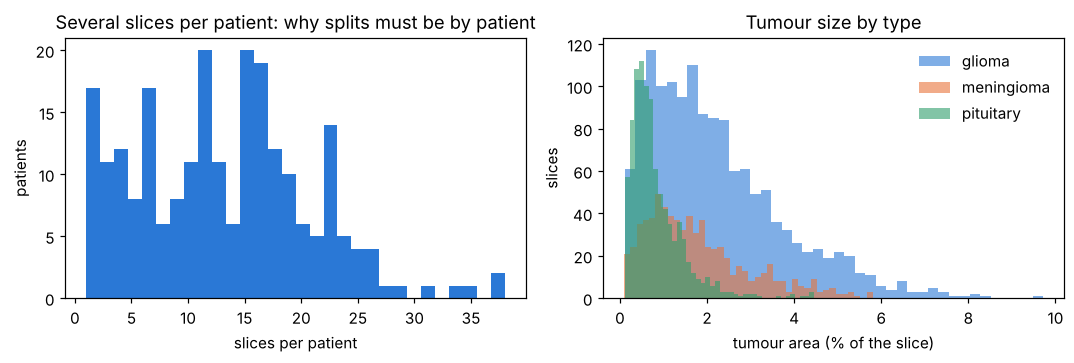

In [7]:
per = meta.groupby("label").agg(slices=("idx", "size"), patients=("pid", "nunique"))
per["slices per patient"] = (per.slices / per.patients).round(1)
per["share of slices"] = (per.slices / per.slices.sum()).round(3)
display(per)
print("image sizes:", meta.groupby(["height", "width"]).size().to_dict())
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
meta.groupby("pid").size().plot.hist(bins=30, ax=ax[0], color="#2a78d6")
ax[0].set(xlabel="slices per patient", ylabel="patients", title="Several slices per patient: why splits must be by patient")
for lab, c in zip(CLASSES, ["#2a78d6", "#e8743b", "#2f9e6b"]):
    ax[1].hist(meta.loc[meta.label == lab, "mask_fraction"] * 100, bins=40, alpha=0.6, label=lab, color=c)
ax[1].set(xlabel="tumour area (% of the slice)", ylabel="slices", title="Tumour size by type")
ax[1].legend(frameon=False)
plt.tight_layout()
plt.show()
display(meta.groupby("label").mask_fraction.describe()[["mean", "50%", "min", "max"]].mul(100).round(2).add_suffix(" (% of slice)"))

**What the exploration shows:**
- Classes are imbalanced (glioma about half of the slices), so the analysis uses balanced accuracy and per-class sensitivity rather than accuracy alone.
- Every patient contributes several slices. Splitting by image would put the same patient in training and test (Part 3 measures exactly that).
- Tumours are small: the median tumour covers 0.7% (pituitary) to 1.8% (glioma) of the slice. That matters for judging the explanation maps in Part 6.

## Part 2b: preprocessing, feature engineering and patient-grouped splitting

In a CNN the features are **learned** from pixels. Feature engineering here means preparing the pixels consistently, and adding augmentation that teaches invariances without changing the anatomy:
1. **Intensity normalisation** (when converting the raw MRI files): clip to the 0.5th–99.5th percentile, then scale to 0–255. This removes scanner-dependent intensity ranges and outlier pixels.
2. **Resize** to 224×224 with antialiasing.
3. **Grey → 3 channels**, because the ImageNet-pretrained backbone expects RGB input.
4. **Augmentation, during training only:** horizontal flip, rotation up to ±14°, zoom ±10%, shift ±5%, contrast ±15%. Vertical flips and strong distortions are avoided because they change the anatomy.

def to_uint8(image: np.ndarray) -> np.ndarray:
    x = image.astype(np.float64)
    lo, hi = np.percentile(x, [0.5, 99.5])
    if hi <= lo:
        hi = lo + 1
    return (np.clip((x - lo) / (hi - lo), 0, 1) * 255).round().astype(np.uint8)



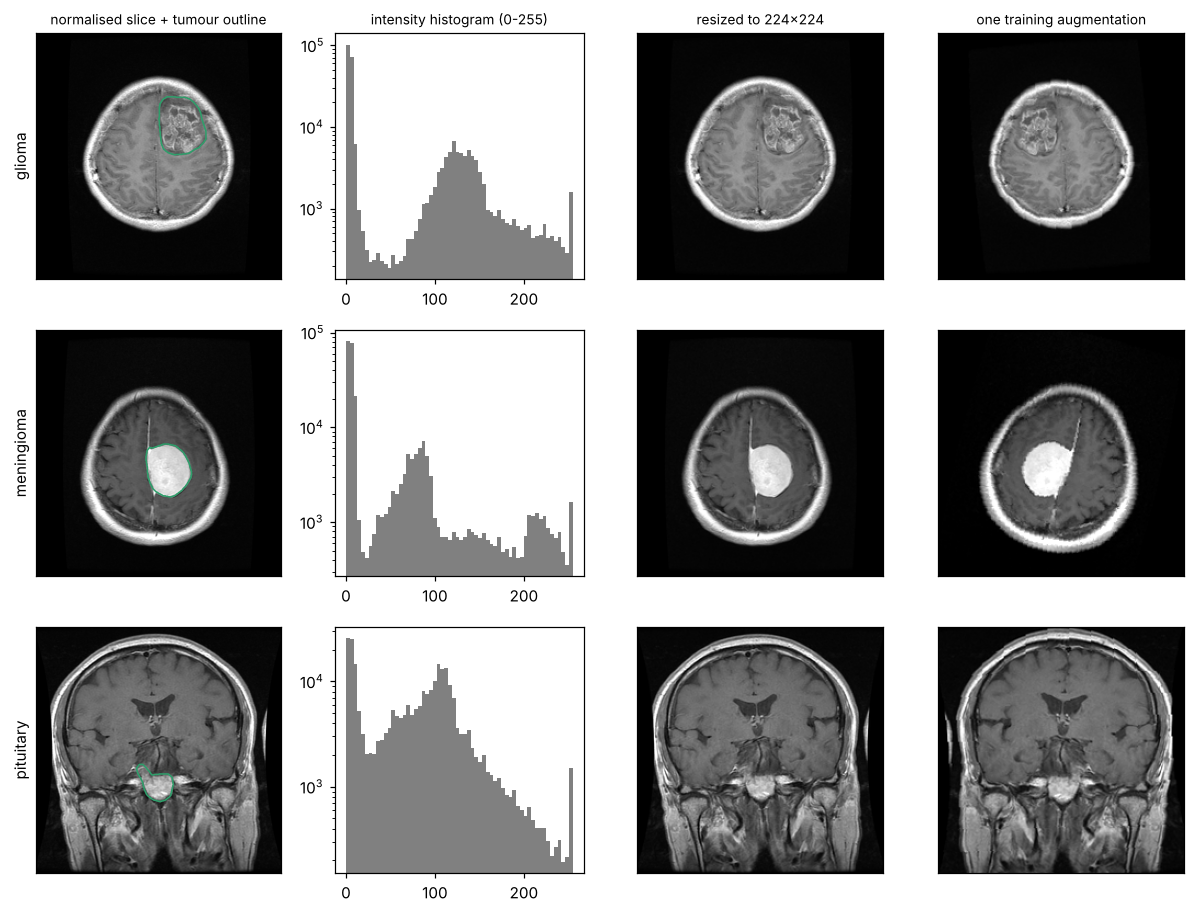

In [8]:
from PIL import Image as PILImage
from brainguard.figshare import to_uint8
import inspect
print(inspect.getsource(to_uint8))
rng = np.random.default_rng(0)
fig, axes = plt.subplots(3, 4, figsize=(11, 8.4))
for r, lab in enumerate(CLASSES):
    img = np.asarray(PILImage.open(DATA / "examples" / f"{lab}_image.png"), dtype=float)
    mask = np.asarray(PILImage.open(DATA / "examples" / f"{lab}_mask.png")) > 0
    resized = np.asarray(PILImage.fromarray(img.astype(np.uint8)).resize((224, 224), PILImage.LANCZOS), dtype=float)
    # one random draw of the training augmentations (flip, rotation, zoom, contrast), for illustration
    aug = PILImage.fromarray(resized.astype(np.uint8)).transpose(PILImage.FLIP_LEFT_RIGHT).rotate(rng.uniform(-14, 14))
    z = rng.uniform(0.9, 1.1); w = int(224 / z); o = (224 - w) // 2
    aug = np.asarray(aug.crop((o, o, o + w, o + w)).resize((224, 224)), dtype=float)
    aug = np.clip((aug - aug.mean()) * rng.uniform(0.85, 1.15) + aug.mean(), 0, 255)
    axes[r, 0].imshow(img, cmap="gray"); axes[r, 0].contour(mask, [0.5], colors="#2f9e6b", linewidths=1)
    axes[r, 1].hist(img.ravel(), bins=60, color="grey"); axes[r, 1].set_yscale("log")
    axes[r, 2].imshow(resized, cmap="gray"); axes[r, 3].imshow(aug, cmap="gray")
    axes[r, 0].set_ylabel(lab)
    for c in (0, 2, 3):
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
for c, t in enumerate(["normalised slice + tumour outline", "intensity histogram (0-255)", "resized to 224x224", "one training augmentation"]):
    axes[0, c].set_title(t, fontsize=9)
plt.tight_layout()
plt.show()

In [9]:
from brainguard.splits import patient_folds, image_folds
pf = patient_folds(meta, 5, 42)
f_tab = meta.assign(fold=pf).groupby("fold").agg(patients=("pid", "nunique"), slices=("idx", "size"),
                                                 glioma=("label", lambda s: (s == "glioma").mean()),
                                                 meningioma=("label", lambda s: (s == "meningioma").mean()),
                                                 pituitary=("label", lambda s: (s == "pituitary").mean())).round(3)
display(f_tab)
print("patients appearing in more than one fold (patient-grouped):", int((meta.assign(fold=pf).groupby("pid").fold.nunique() > 1).sum()))
imf = image_folds(meta, 5, 42)
leak = []
for kf in range(5):
    test_p = set(meta.pid[imf == kf]); train_p = set(meta.pid[imf != kf])
    leak.append(np.mean([p in train_p for p in meta.pid[imf == kf]]))
print(f"image-level folds: share of test slices whose patient is also in training = {np.mean(leak):.1%}")

,patients,slices,glioma,meningioma,pituitary
fold,,,,,
0,47,613,0.467,0.232,0.302
1,47,614,0.466,0.231,0.303
2,46,611,0.465,0.232,0.303
3,46,613,0.465,0.230,0.305
4,47,613,0.465,0.230,0.305


patients appearing in more than one fold (patient-grouped): 0
image-level folds: share of test slices whose patient is also in training = 99.7%


With patient-grouped folds, no patient is ever on both sides, and each fold keeps the same class mix. With image-level folds, almost every test slice has a sibling slice from the same patient in training. That is the leakage measured in Part 3.

## Part 2: the final model (ResNet50) on patients it has never seen

In [10]:
main = pd.read_csv(PRED / "resnet50_final.csv", dtype={"pid": str})          # final model
effnet = pd.read_csv(PRED / "effnet_patient.csv", dtype={"pid": str})        # pre-specified model, used for H1-H3
print(f"{len(main):,} images from {main.pid.nunique()} patients")
print("Any patient appearing in more than one fold?", (main.groupby("pid").fold.nunique() > 1).any())
pred = predicted(main)
print(f"accuracy {accuracy_score(main.label, pred):.3f}   balanced accuracy {balanced_accuracy_score(main.label, pred):.3f}")
cm = pd.DataFrame(confusion_matrix(main.label, pred, labels=CLASSES), index=[f"true {c}" for c in CLASSES], columns=[f"pred {c}" for c in CLASSES])
display(cm)
sens = {c: (pred[main.label == c] == c).mean() for c in CLASSES}
print("sensitivity per tumour type:", {k: round(float(v), 3) for k, v in sens.items()})

3,064 images from 233 patients
Any patient appearing in more than one fold? False
accuracy 0.918   balanced accuracy 0.901


,pred glioma,pred meningioma,pred pituitary
true glioma,1354,61,11
true meningioma,79,554,75
true pituitary,7,19,904


sensitivity per tumour type: {'glioma': 0.95, 'meningioma': 0.782, 'pituitary': 0.972}


From the report (patient-level bootstrap, 95% CI): balanced accuracy 0.901 (0.872-0.925), macro AUC 0.983, ECE 0.036


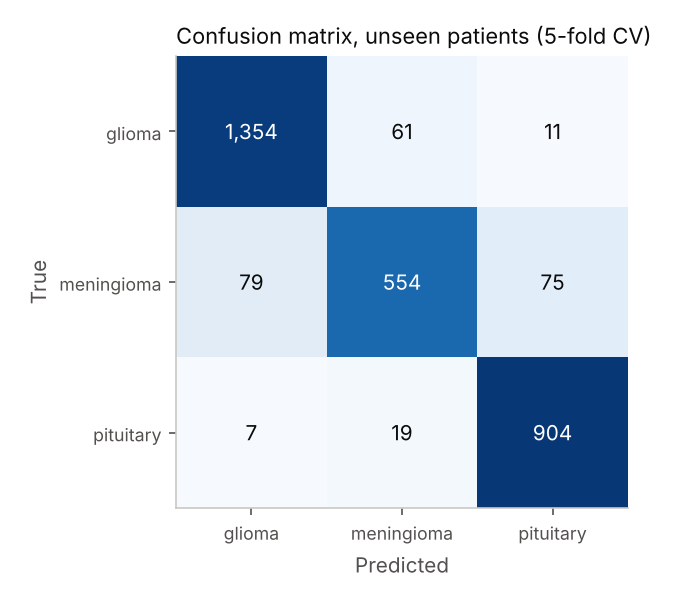

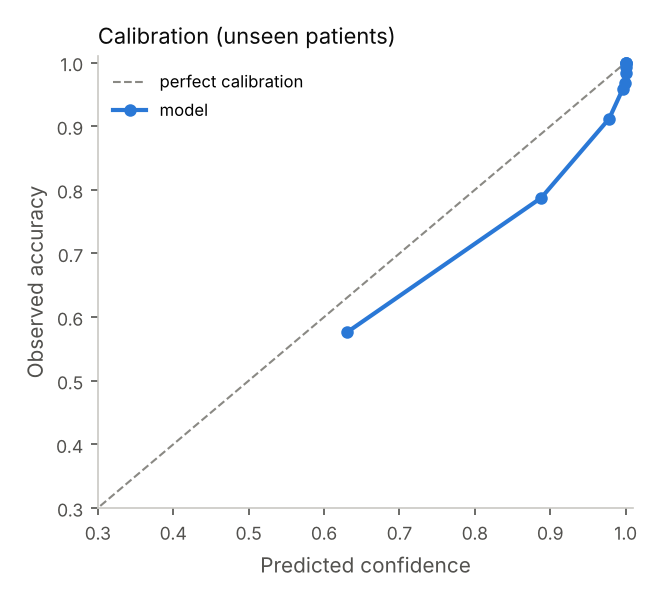

In [11]:
m = res["main"]
print(f"From the report (patient-level bootstrap, 95% CI): balanced accuracy {m['balanced_accuracy']['value']:.3f} "
      f"({m['balanced_accuracy']['ci'][0]:.3f}-{m['balanced_accuracy']['ci'][1]:.3f}), macro AUC {m['macro_auc']['value']:.3f}, ECE {m['ece']:.3f}")
display(Image(filename=str(FIG / "confusion_matrix.png")))
display(Image(filename=str(FIG / "calibration.png")))

Meningioma is the weak point: about 1 in 5 is classified as another type, with errors in both directions (glioma and pituitary). Calibration is good at high confidence (at least 99% confident: right 98.5% of the time) and over-confident in the middle of the range.

## Part 3: leakage, measured directly

EfficientNetB0 with the same settings is trained twice: once with folds split by **patient** (the honest way), and once by **image**, so that slices of one patient fall into both training and test. The gap is the leakage.

balanced accuracy, patient-level split: 0.865
balanced accuracy, image-level split:   0.916   -> leakage inflation +0.052


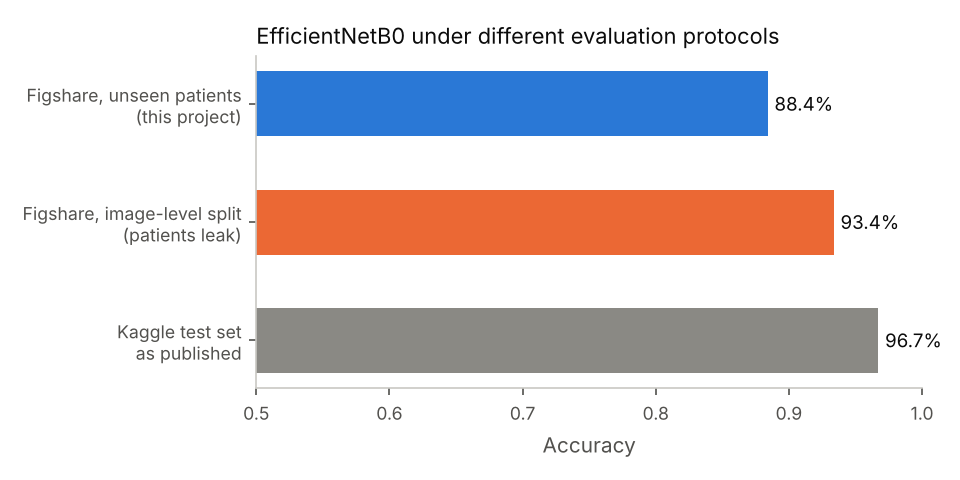

In [12]:
img = pd.read_csv(PRED / "effnet_image.csv", dtype={"pid": str})
both = effnet.merge(img[["idx"] + [f"p_{c}" for c in CLASSES]], on="idx", suffixes=("_patient", "_image"))
acc_p = balanced_accuracy_score(both.label, np.array(CLASSES)[both[[f"p_{c}_patient" for c in CLASSES]].to_numpy().argmax(1)])
acc_i = balanced_accuracy_score(both.label, np.array(CLASSES)[both[[f"p_{c}_image" for c in CLASSES]].to_numpy().argmax(1)])
print(f"balanced accuracy, patient-level split: {acc_p:.3f}")
print(f"balanced accuracy, image-level split:   {acc_i:.3f}   -> leakage inflation {acc_i - acc_p:+.3f}")
display(Image(filename=str(FIG / "protocol_comparison.png")))

In [13]:
kag = pd.read_csv(PRED / "kaggle_effnet.csv", dtype={"pid": str})
kclasses = ["glioma", "meningioma", "notumor", "pituitary"]
kag["correct"] = predicted(kag, kclasses) == kag.label
print(f"Kaggle Testing accuracy as published: {kag.correct.mean():.3f}")
print(kag.groupby("copy_in_train").correct.agg(["mean", "size"]).rename(index={True: "has a near-copy in Training", False: "no copy"}).round(3))

Kaggle Testing accuracy as published: 0.967
                              mean  size
copy_in_train                           
no copy                      0.937   601
has a near-copy in Training  0.993   710


On the Kaggle benchmark, test images that have a near-copy in the training set are classified almost perfectly. That is memorisation, not diagnosis.

## Part 4: does transfer learning or class weighting help?

In [14]:
rows = []
for name, label in (("effnet_patient", "EfficientNetB0 (main)"), ("cnn_patient", "Baseline CNN (original BrainGuard)"), ("effnet_patient_cw", "EfficientNetB0 + class weights")):
    d = pd.read_csv(PRED / f"{name}.csv", dtype={"pid": str})
    p = predicted(d)
    rows.append({"model": label, "accuracy": accuracy_score(d.label, p), "balanced accuracy": balanced_accuracy_score(d.label, p),
                 "meningioma sensitivity": (p[d.label == "meningioma"] == "meningioma").mean()})
display(pd.DataFrame(rows).round(3))

,model,accuracy,balanced accuracy,meningioma sensitivity
0,EfficientNetB0 (main),0.884,0.865,0.699
1,Baseline CNN (original BrainGuard),0.883,0.872,0.766
2,EfficientNetB0 + class weights,0.890,0.876,0.740


In [15]:
for k in ("compare_cnn_patient", "compare_effnet_patient_cw"):
    c = res[k]; d = c["diff_balanced_accuracy"]
    print(f"{c['a']} vs {c['b']}: balanced accuracy {d['value']:+.3f} (bootstrap 95% CI {d['ci'][0]:+.3f} to {d['ci'][1]:+.3f}); "
          f"McNemar p = {c['mcnemar']['p']:.2f}")

cnn_patient vs effnet_patient: balanced accuracy +0.008 (bootstrap 95% CI -0.017 to +0.031); McNemar p = 0.96
effnet_patient_cw vs effnet_patient: balanced accuracy +0.011 (bootstrap 95% CI +0.001 to +0.021); McNemar p = 0.13


The small original CNN is as good as EfficientNetB0 once both are evaluated properly. Class weighting gives a small gain in balanced accuracy (+1.1 points), and its bootstrap interval sits just above zero. But the paired McNemar test on correct/incorrect predictions is not significant after Holm correction (Part 7). The evidence for a benefit is therefore weak, and the main model stays unweighted.

## Part 4b: is EfficientNetB0 the right backbone? (architecture screen)

Four more ImageNet backbones were trained on **the same patient folds** with the same augmentation, head, two-phase fine-tuning and early stopping (`notebooks/run_architectures_on_colab.ipynb`). Because every model predicts the same 3,064 images, the comparison with EfficientNetB0 is paired: a patient-level bootstrap for the difference in balanced accuracy, and McNemar on per-image correctness, Holm-adjusted within the screen.

,model,balanced accuracy,95% CI,diff vs EfficientNetB0,diff 95% CI,McNemar p (Holm),macro AUC,meningioma sensitivity,ECE,params (M),min per fold
2,ResNet50 (selected),0.907,0.878-0.932,0.043,+0.020 to +0.065,0.000,0.982,0.852,0.053,23.594,4.687
5,ConvNeXt-Tiny,0.899,0.873-0.921,0.034,+0.013 to +0.056,0.000,0.980,0.784,0.044,27.822,13.114
3,DenseNet121,0.893,0.864-0.918,0.029,+0.009 to +0.049,0.000,0.977,0.770,0.032,7.041,4.564
4,MobileNetV3-Large,0.878,0.847-0.906,0.013,-0.005 to +0.032,0.719,0.976,0.754,0.050,2.999,1.888
1,Baseline CNN (original notebook),0.872,0.840-0.901,0.008,-0.017 to +0.031,0.957,0.968,0.766,0.050,NaN,NaN
0,EfficientNetB0 (pre-specified model),0.865,0.835-0.891,NaN,reference,NaN,0.971,0.699,0.045,NaN,NaN


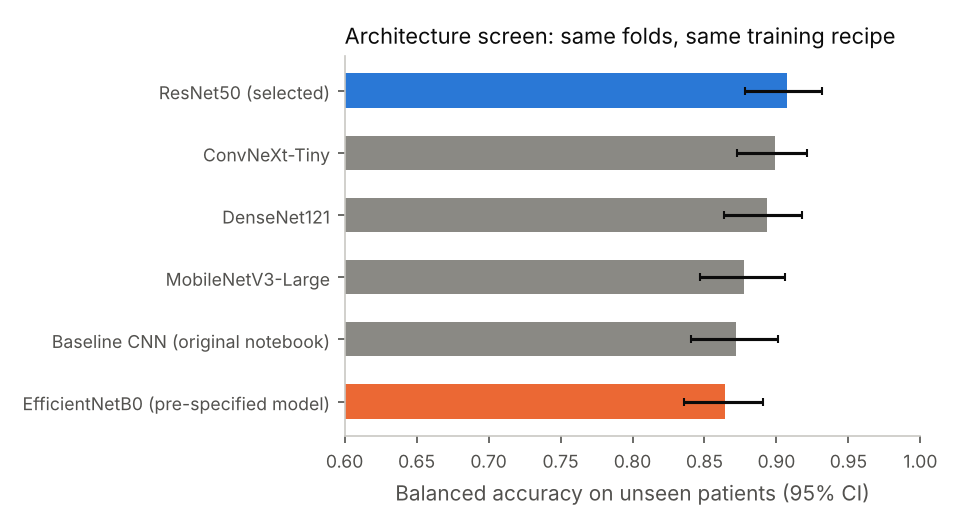

In [16]:
arch = pd.DataFrame([{
    "model": a["label"],
    "balanced accuracy": a["balanced_accuracy"]["value"],
    "95% CI": f"{a['balanced_accuracy']['ci'][0]:.3f}-{a['balanced_accuracy']['ci'][1]:.3f}",
    "diff vs EfficientNetB0": a.get("diff_vs_main", {}).get("value"),
    "diff 95% CI": (f"{a['diff_vs_main']['ci'][0]:+.3f} to {a['diff_vs_main']['ci'][1]:+.3f}" if "diff_vs_main" in a else "reference"),
    "McNemar p (Holm)": a.get("mcnemar_p_holm"),
    "macro AUC": a["macro_auc"]["value"],
    "meningioma sensitivity": a["meningioma_sensitivity"],
    "ECE": a["ece"],
    "params (M)": a["n_params"] / 1e6 if "n_params" in a else None,
    "min per fold": a.get("minutes_per_fold"),
} for a in res["architectures"]]).sort_values("balanced accuracy", ascending=False)
display(arch.round(3))
display(Image(filename=str(FIG / "architectures.png"), width=600))

**What the screen shows:**
- ResNet50, ConvNeXt-Tiny and DenseNet121 are all clearly better than EfficientNetB0 (bootstrap intervals for the gain exclude zero). ResNet50 is the best: about +4 points of balanced accuracy, mostly from meningioma (85% sensitivity against 70%).
- MobileNetV3 and the original CNN are not distinguishable from EfficientNetB0.
- The bootstrap interval is the evidence to trust: McNemar treats slices as independent, and slices of one patient are not, so its p-values are optimistic.
- **ResNet50 was selected as the final model** and retrained on the same folds with its fold models saved. That second run (Part 2) gave 90.1% balanced accuracy against 90.7% in the screen, so the lead over EfficientNetB0 (+3.7 points, CI +1.3 to +6.2) is not a lucky run. Meningioma sensitivity moved more between runs (85% vs 78%).
- Because it was selected on these folds, its estimate is slightly optimistic; only an external test set removes that bias.
- So "transfer learning doesn't help" (Part 4) is true of EfficientNetB0, not of transfer learning in general.

In [17]:
r = res["final_replication"]
print(f"ResNet50 screen run {r['balanced_accuracy_screen_run']:.3f}, final run {r['balanced_accuracy_final_run']:.3f}; "
      f"same predicted class for {r['prediction_agreement']:.1%} of images")

ResNet50 screen run 0.907, final run 0.901; same predicted class for 93.8% of images


## Part 5: robustness to image quality

,balanced accuracy,change_vs_clean
perturbation,,
gaussian noise sd 16,0.795,-0.106
blur sigma 1.5,0.809,-0.092
gaussian noise sd 8,0.841,-0.060
half resolution,0.859,-0.042
JPEG quality 30,0.890,-0.011
gamma 1.5,0.892,-0.009
brightness -15%,0.892,-0.009
contrast x0.7,0.897,-0.005
brightness +15%,0.897,-0.004


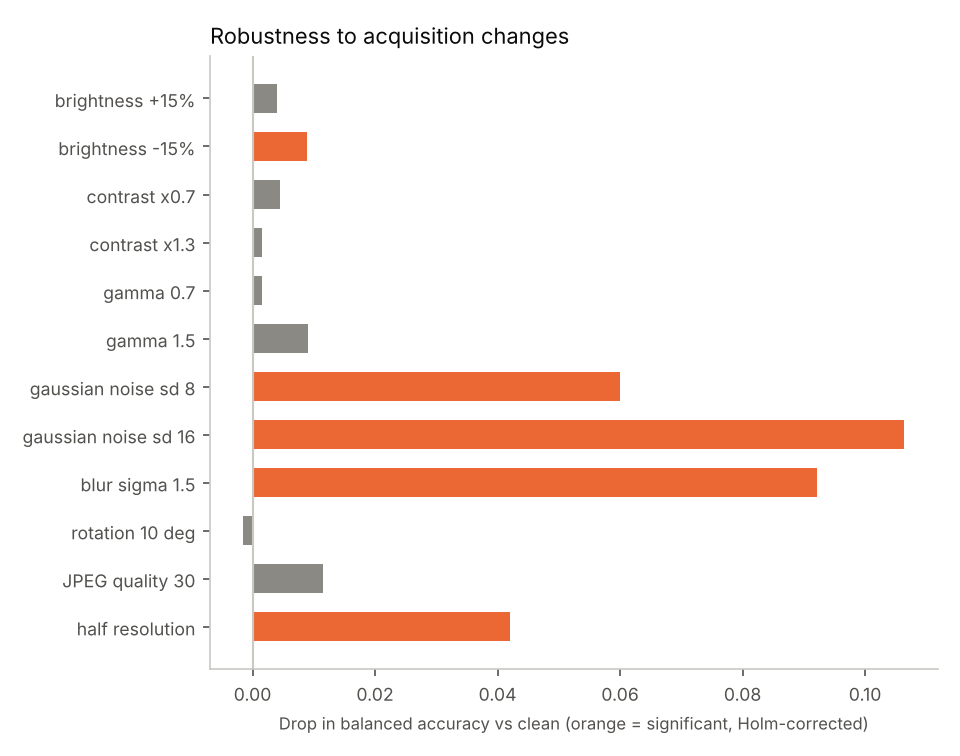

In [18]:
rob = pd.read_csv(PRED / "robustness_resnet50_final.csv", dtype={"pid": str})
rob["pred"] = predicted(rob)
lab = main.set_index("idx").label
rob["label"] = rob.idx.map(lab)
table = rob.groupby("perturbation").apply(lambda g: balanced_accuracy_score(g.label, g.pred), include_groups=False).sort_values()
display((table.to_frame("balanced accuracy").assign(change_vs_clean=lambda t: t["balanced accuracy"] - table["clean"])).round(3))
display(Image(filename=str(FIG / "robustness.png")))

Brightness, contrast, gamma, rotation and JPEG compression barely matter (≤ 1.1 points). Noise, blur and lower resolution cost 4–11 points, which is the main risk if the model met images from a different scanner. ResNet50 is steadier than EfficientNetB0 under blur and contrast changes, but more sensitive to noise.

## Part 6: do the explanations point at the tumour?

150 held-out images, each explained by the fold model that never saw the patient
median tumour area (chance level):            1.2%
median SHAP attribution inside the tumour:      4.6%
median Grad-CAM attribution inside the tumour:  4.5%
peak of the map inside the tumour: SHAP 42.0%, Grad-CAM 28.7% (chance 2.2%)

Sanity check (similarity of maps from the trained model vs a randomly initialised one; low = depends on learning):
  SHAP 0.53   Grad-CAM -0.06


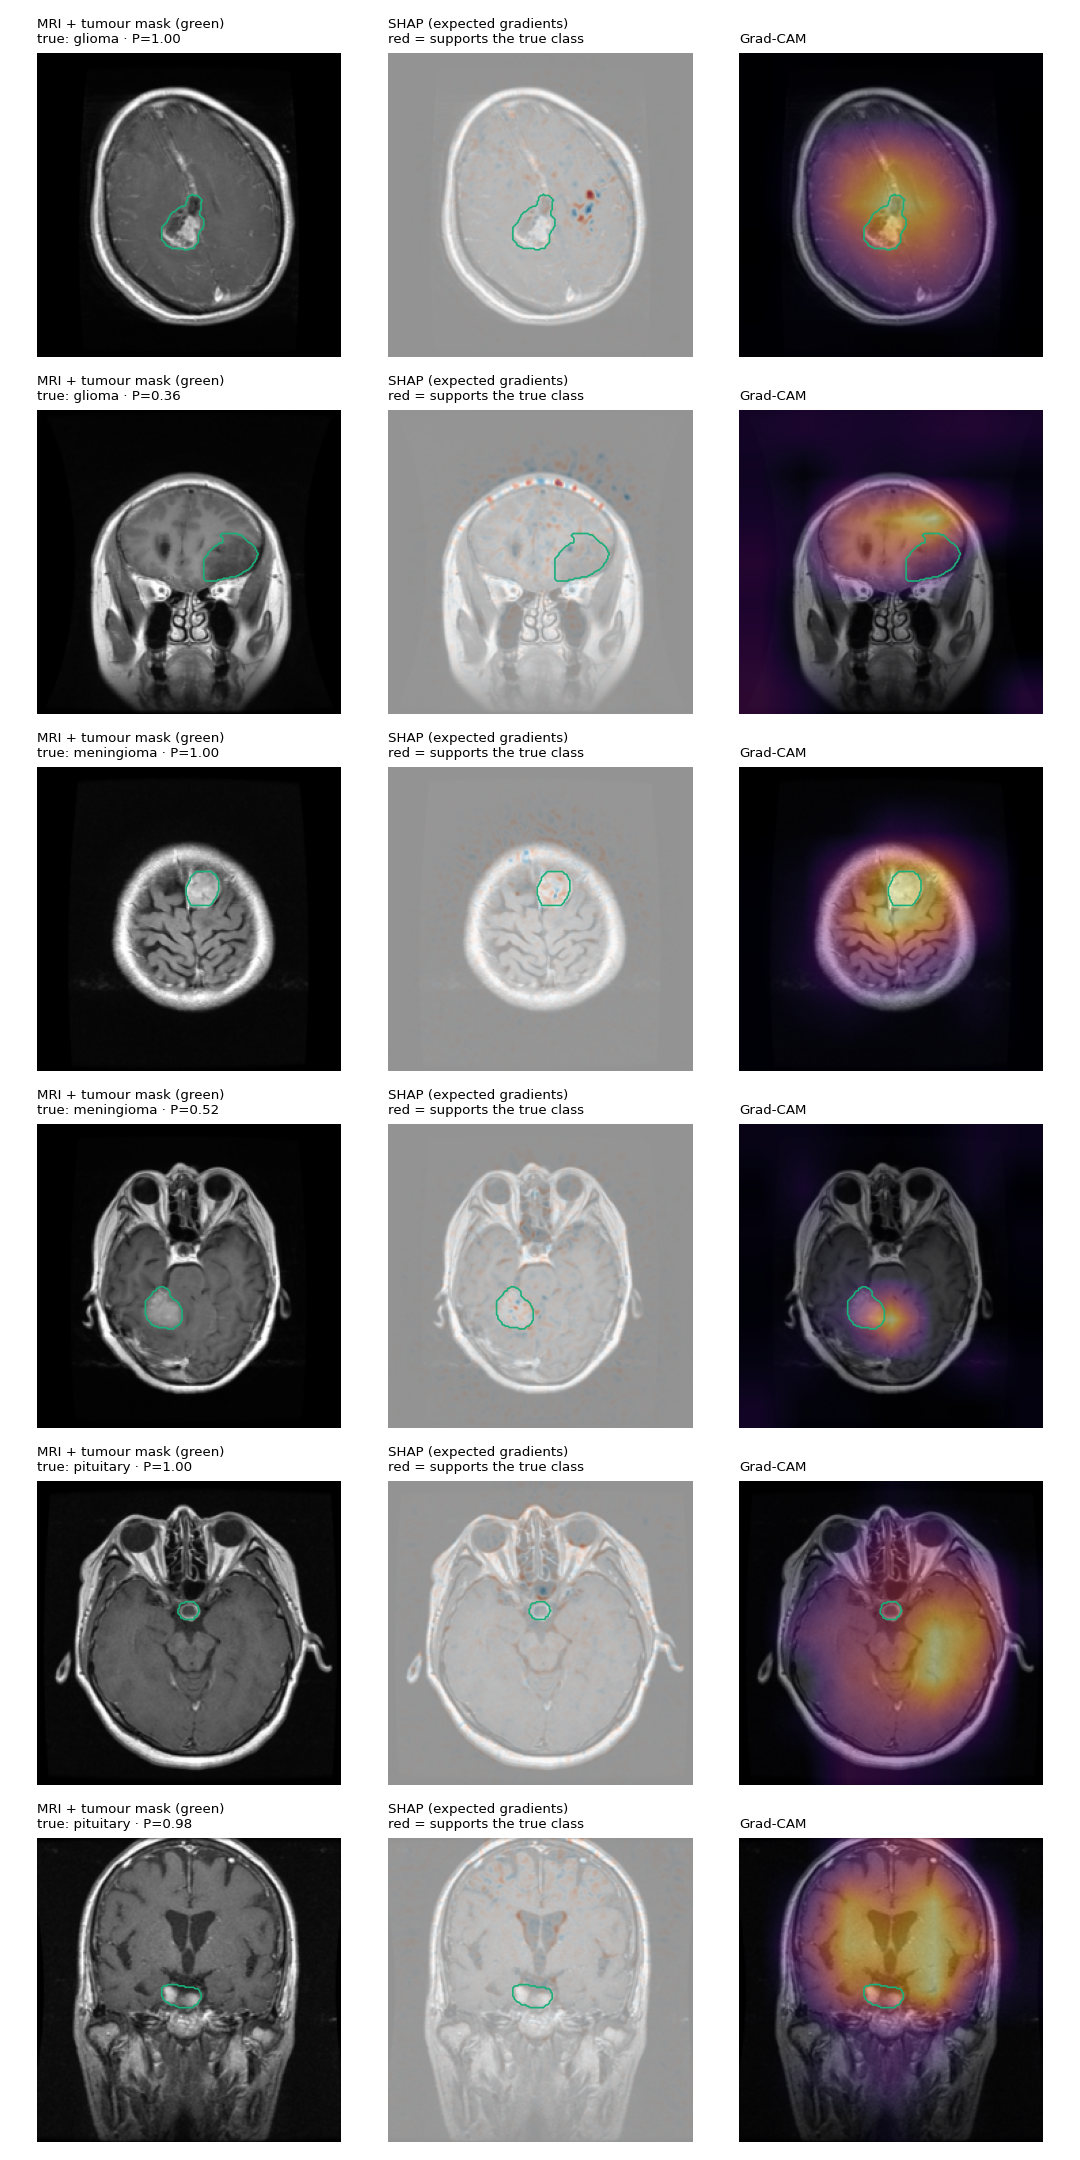

In [19]:
em = pd.read_csv(ROOT / "results" / "explain" / "resnet50_final" / "explain_metrics.csv")
sanity = pd.read_csv(ROOT / "results" / "explain" / "resnet50_final" / "explain_sanity.csv")
print(f"{len(em)} held-out images, each explained by the fold model that never saw the patient")
print(f"median tumour area (chance level):            {em.mask_fraction.median():.1%}")
print(f"median SHAP attribution inside the tumour:      {em.shap_energy_in_mask.median():.1%}")
print(f"median Grad-CAM attribution inside the tumour:  {em.cam_energy_in_mask.median():.1%}")
print(f"peak of the map inside the tumour: SHAP {em.shap_pointing_hit.mean():.1%}, Grad-CAM {em.cam_pointing_hit.mean():.1%} (chance {em.pointing_chance.mean():.1%})")
print(f"\nSanity check (similarity of maps from the trained model vs a randomly initialised one; low = depends on learning):")
print(f"  SHAP {sanity.shap_similarity_trained_vs_random.median():.2f}   Grad-CAM {sanity.cam_similarity_trained_vs_random.median():.2f}")
display(Image(filename=str(FIG / "explain_examples.png"), width=600))

Both maps focus on the tumour about 3.6× more than chance, and more than EfficientNetB0's did, but most of the attribution still falls outside it. **Grad-CAM passes the sanity check clearly; SHAP is borderline** (0.53, just above the 0.5 line): its maps partly show image structure rather than the model's reasoning. In the figure, Grad-CAM covers the glioma and meningioma cases but spreads widely for pituitary tumours. Explanation maps should be tested, not trusted on sight.

## Part 7: hypothesis tests and conclusions

In [20]:
display(pd.DataFrame(res["hypotheses"])[["id", "hypothesis", "evidence", "p_holm", "verdict"]].sort_values("id"))

,id,hypothesis,evidence,p_holm,verdict
1,H1,Image-level CV overstates accuracy versus patient-level CV (leakage),balanced accuracy 91.6% (effnet_image) vs 86.5% (EfficientNetB0); McNemar 201/49 discordant,2.928483e-22,supported
2,H2,Transfer learning (EfficientNetB0) beats the baseline CNN,balanced accuracy 87.2% (cnn_patient) vs 86.5% (EfficientNetB0); McNemar 171/173 discordant,1.000000e+00,not supported
3,H3,Class weighting improves balanced accuracy,balanced accuracy 87.6% (effnet_patient_cw) vs 86.5% (EfficientNetB0); McNemar 73/55 discordant,3.978744e-01,not supported
0,H4,Meningioma is detected less reliably than the other classes,sensitivity difference -17.6% (CI -25.4% to -10.8%),2.000000e-03,supported
4,H5a,Kaggle accuracy is higher when the image has a near-copy in Training,99.3% vs 93.7%,2.746774e-08,supported
5,H5b,Kaggle accuracy is higher when the image's patient is in Training,97.7% vs 96.6%,1.000000e+00,not supported
6,H6,SHAP attribution concentrates on the tumour more than chance,median 4.6% inside vs 1.2% area,1.689599e-25,supported


**Conclusions**
1. **The popular benchmark overstates accuracy**, through duplicate images, shared patients and a file-size shortcut.
2. **The final ResNet50 model reaches 90.1% balanced accuracy on new patients** (macro AUC 0.983); leakage alone would have added about 5 points to any model.
3. **The backbone matters.** EfficientNetB0 is no better than the original small CNN; ResNet50 beats both by about 3–4 points, confirmed in a second training run.
4. **Meningioma is the clinical weak point** (78–85% sensitivity across two runs), so the model must not be used to rule it out.
5. **Image quality is the deployment risk**, and explanations need sanity checks before anyone relies on them.

See `MODEL_CARD.md` for intended use and limitations.